# ECG Disease Prediction: Patch Transformer + LLM Report

**Natdanai (MUICT) - trial project for Aj. Tipajin**

This notebook only *loads* saved results and figures. No training happens here.
Run it from the `notebooks/` folder after the pipeline has been run (see `README.md`).

**Contents:** 1. Dataset - 2. Pipeline - 3. Preprocessing - 4. Results - 5. Per-class results -
6. Training curves - 7. Explainability - 8. LLM report - 9. Bonus: anomaly detection - 10. Limitations

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path("..")            # project root (this notebook lives in notebooks/)
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"
CLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]
MODELS = {"cnn": "1D-CNN", "transformer": "Patch Transformer", "hybrid": "Hybrid CNN+Transformer"}

def load_metrics(run):
    with open(RESULTS / run / "metrics.json") as f:
        return json.load(f)

## 1. Dataset: PTB-XL v1.0.3

- 21,799 clinical 12-lead ECGs, 10 seconds each. I use the 100 Hz version: each ECG is an array of shape `(1000, 12)`.
- Labels: 5 diagnostic superclasses, **multi-label** (one ECG can have several).
- 411 ECGs have no diagnostic superclass and are dropped, leaving **21,388**.
- Official split by `strat_fold`: folds 1-8 train, fold 9 validation, fold 10 test. Each patient is in exactly one fold, so there is no patient leakage.

| Label | Meaning |
|---|---|
| NORM | Normal ECG |
| MI | Myocardial infarction |
| STTC | ST/T change |
| CD | Conduction disturbance |
| HYP | Hypertrophy |

In [2]:
counts = pd.read_csv(RESULTS / "class_counts.csv", index_col="split")
display(counts)
share = (100 * counts[CLASSES].sum() / counts["n_ecgs"].sum()).round(1)
print("Share of all ECGs that carry each label (%):")
print(share.to_string())

,n_ecgs,NORM,MI,STTC,CD,HYP
split,,,,,,
train,17084,7596,4379,4186,3907,2119
val,2146,955,540,528,495,268
test,2158,963,550,521,496,262


Share of all ECGs that carry each label (%):
NORM    44.5
MI      25.6
STTC    24.5
CD      22.9
HYP     12.4


24.1 % of the ECGs have two or more superclasses. The classes are imbalanced: NORM is the most common, HYP the rarest.

![Class distribution](../figures/class_distribution.png)

One example per class (leads II and V2):

![Example ECGs](../figures/example_ecgs.png)

## 2. Pipeline

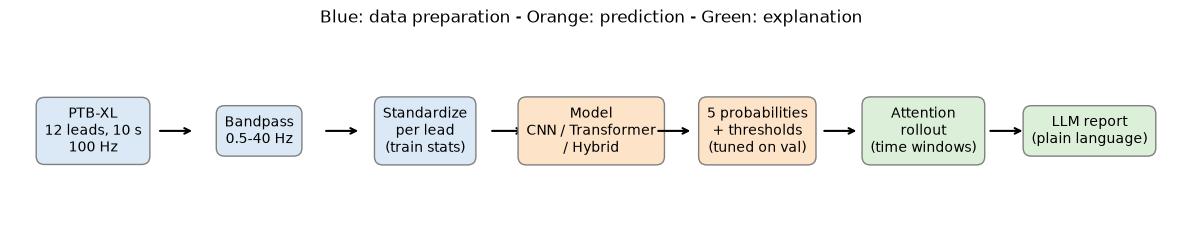

In [3]:
steps = [
    ("PTB-XL\n12 leads, 10 s\n100 Hz", "#dbe9f6"),
    ("Bandpass\n0.5-40 Hz", "#dbe9f6"),
    ("Standardize\nper lead\n(train stats)", "#dbe9f6"),
    ("Model\nCNN / Transformer\n/ Hybrid", "#fde3c8"),
    ("5 probabilities\n+ thresholds\n(tuned on val)", "#fde3c8"),
    ("Attention\nrollout\n(time windows)", "#dcefd9"),
    ("LLM report\n(plain language)", "#dcefd9"),
]
fig, ax = plt.subplots(figsize=(15, 2.6))
for i, (text, colour) in enumerate(steps):
    ax.text(i * 2.2, 0, text, ha="center", va="center", fontsize=10,
            bbox=dict(boxstyle="round,pad=0.6", facecolor=colour, edgecolor="gray"))
    if i < len(steps) - 1:
        ax.annotate("", xy=(i * 2.2 + 1.35, 0), xytext=(i * 2.2 + 0.85, 0),
                    arrowprops=dict(arrowstyle="->", color="black", lw=1.5))
ax.set_xlim(-1.1, (len(steps) - 1) * 2.2 + 1.1)
ax.set_ylim(-1, 1)
ax.axis("off")
ax.set_title("Blue: data preparation - Orange: prediction - Green: explanation")
plt.show()

## 3. Preprocessing

1. **Bandpass filter 0.5-40 Hz** (Butterworth, order 3, zero-phase): removes baseline drift and high-frequency noise.
2. **Standardization per lead**, with mean and std computed on the **training folds only**.

![Before and after filtering](../figures/preprocessing_before_after.png)

## 4. Results

All numbers are on the official test fold (fold 10, 2,158 ECGs), which was used once per model.
Model choices (pos_weight, patch size) were made on the validation fold.

In [4]:
display(Markdown((RESULTS / "final_table.md").read_text(encoding="utf-8")))

# Final results on the PTB-XL test fold (fold 10)

| Model | Parameters | Train time | Macro AUROC | AUROC NORM | AUROC MI | AUROC STTC | AUROC CD | AUROC HYP | Macro F1 |
|---|---|---|---|---|---|---|---|---|---|
| 1D-CNN (baseline) | 190,757 | 30 s | **0.9272** | 0.946 | 0.923 | 0.939 | 0.922 | 0.906 | 0.748 |
| Patch Transformer | 610,565 | 50 s | **0.8901** | 0.918 | 0.857 | 0.915 | 0.880 | 0.881 | 0.687 |
| Hybrid CNN + Transformer | 622,117 | 99 s | **0.9235** | 0.945 | 0.919 | 0.931 | 0.920 | 0.902 | 0.735 |

- Test fold = official PTB-XL fold 10 (2,158 ECGs), used once per model.
- Thresholds for F1 were tuned per class on the validation fold (fold 9).
- Train time: one run on an NVIDIA RTX 4050 laptop GPU, seed 42, with early stopping.
- Published deep models reach about 0.93 macro AUROC on this task.


![Model comparison](../figures/model_comparison.png)

**Reading the result**
- The simple **CNN is the best model (0.927)**, close to the ~0.93 of published deep models.
- The **pure patch Transformer is clearly worse (0.890)**: it has no built-in knowledge of local wave shapes and overfits with 17,000 training ECGs.
- The **hybrid recovers the gap (0.924)**: adding a CNN front-end before the Transformer fixes the problem. The 0.004 difference to the CNN is too small to be meaningful for a single run.

Experiments that were judged on validation only (never run on the test fold):

In [5]:
summary = pd.read_csv(RESULTS / "summary.csv")
display(summary[["run", "model", "params", "best_epoch", "val_macro_auroc", "test_macro_auroc"]])

,run,model,params,best_epoch,val_macro_auroc,test_macro_auroc
0,cnn,cnn,190757,12,0.9327,0.9272
1,cnn_posweight,cnn,190757,8,0.9307,NaN
2,transformer_patch25,transformer,574725,11,0.9051,NaN
3,transformer,transformer,610565,11,0.9003,0.8901
4,hybrid,hybrid,622117,12,0.9277,0.9235


## 5. Per-class results

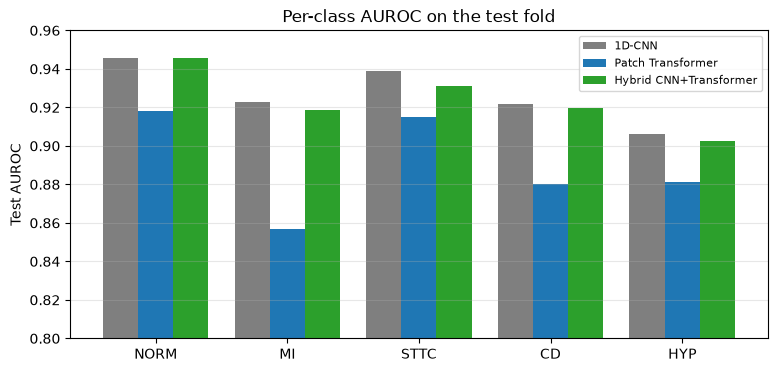

,1D-CNN,Patch Transformer,Hybrid CNN+Transformer
NORM,0.946,0.918,0.945
MI,0.923,0.857,0.919
STTC,0.939,0.915,0.931
CD,0.922,0.880,0.920
HYP,0.906,0.881,0.902


In [6]:
auroc = pd.DataFrame({MODELS[r]: load_metrics(r)["test_auroc_per_class"] for r in MODELS}).loc[CLASSES]
ax = auroc.plot.bar(figsize=(9, 4), ylim=(0.80, 0.96), rot=0, width=0.8,
                    color=["tab:gray", "tab:blue", "tab:green"])
ax.set_ylabel("Test AUROC")
ax.set_title("Per-class AUROC on the test fold")
ax.legend(loc="upper right", fontsize=8)
ax.grid(axis="y", alpha=0.3)
plt.show()
display(auroc.round(3))

In [7]:
# F1, precision and recall of the best model (CNN), using the thresholds tuned on validation
best = load_metrics("cnn")
table = pd.DataFrame(best["test_per_class"]).T.loc[CLASSES].round(3)
table["threshold"] = pd.Series(best["thresholds"]).round(2)
table["test AUROC"] = pd.Series(best["test_auroc_per_class"]).round(3)
display(table)

,f1,precision,recall,threshold,test AUROC
NORM,0.863,0.803,0.933,0.43,0.946
MI,0.750,0.723,0.778,0.35,0.923
STTC,0.770,0.714,0.835,0.25,0.939
CD,0.758,0.752,0.764,0.56,0.922
HYP,0.602,0.601,0.603,0.17,0.906


- **HYP is the hardest class** for every model (lowest AUROC and F1). It is the rarest class and it usually occurs together with other labels.
- **NORM is the easiest.**
- MI is where the pure Transformer loses the most (0.857 vs 0.923 for the CNN).

ROC curves of the best model (CNN):

![ROC curves](../figures/roc_curves.png)

## 6. Training curves

Early stopping keeps the checkpoint with the best validation macro AUROC (dashed line).
All three models start to overfit after roughly 10 epochs: the training loss keeps falling while the validation loss rises.

![CNN](../figures/training_curves_cnn.png)
![Transformer](../figures/training_curves_transformer.png)
![Hybrid](../figures/training_curves_hybrid.png)

## 7. Explainability: attention rollout

Attention rollout multiplies the head-averaged attention matrices of all layers (adding the identity for the residual connections) and reads the [CLS] row: how much each time patch contributes to the prediction. Darker red = more attention. The bar chart shows the share per 0.5 s window; the dashed line (5 %) is what equal attention would look like.

In [8]:
stats = {MODELS[r]: json.load(open(RESULTS / f"attention_stats_{r}.json")) for r in ["transformer", "hybrid"]}
display(pd.DataFrame({
    name: {
        "strongest 0.5 s window, average share (%) [equal = 5]": round(100 * s["mean_top_window_share"], 1),
        "correlation attention vs. signal energy (Spearman)": round(s["mean_energy_correlation"], 2),
        "ECGs with positive correlation (%)": round(100 * s["share_of_ecgs_with_positive_correlation"]),
    } for name, s in stats.items()
}))

,Patch Transformer,Hybrid CNN+Transformer
"strongest 0.5 s window, average share (%) [equal = 5]",7.70,6.9
correlation attention vs. signal energy (Spearman),0.19,0.5
ECGs with positive correlation (%),73.00,89.0


### Patch Transformer (20 patches of 0.5 s)

The attention is **diffuse**: no window gets much more than the 5 % of equal attention, and a 0.5 s patch is too coarse to separate the ST segment from the QRS complex.

MI, correctly predicted. Note that the strongest window (9.5-10.0 s) is a noise artifact:

![](../figures/attention_MI_11238.png)

STTC, correctly predicted:

![](../figures/attention_STTC_16591.png)

CD, correctly predicted:

![](../figures/attention_CD_2626.png)

A missed MI (the model says NORM 0.98). The attention map looks no different from a correct one:

![](../figures/attention_misclassified_missedMI_13819.png)

### Hybrid model (125 tokens of 0.08 s)

The attention is **locked to the heartbeat**: narrow bands on and around every QRS complex.

CD: the bands sit on the wide, notched QRS complexes. This makes medical sense, because conduction disturbances are diagnosed from the QRS width and shape:

![](../figures/attention_hybrid_CD_18671.png)

MI: the bands sit at the QRS complex of every beat, *not* on the ST segment after it:

![](../figures/attention_hybrid_MI_6552.png)

STTC:

![](../figures/attention_hybrid_STTC_17323.png)

**Honest conclusion:** the maps show that the model looks at heartbeats rather than at noise or at a fixed position, and for CD the focus on the QRS is medically sensible. They do **not** show that the model looks at the ST segment for MI. Attention maps are a sanity check, not proof of clinical reasoning.

## 8. LLM report

For each ECG only structured facts are passed to the report generator: predicted classes, probabilities, tuned thresholds, the top 3 attended time windows, and the patient's age and sex. Rules: plain language, 3-5 sentences, mention the confidence, name the time segments, invent nothing, end with the disclaimer.

The text is written by **Qwen2.5-1.5B-Instruct**, a free open model that runs locally on my laptop (no API key, no data leaves the machine). Every text is then **checked by code**: disclaimer, 3-5 sentences in one paragraph, only numbers from the inputs, predicted classes and a time window named, correct confidence words, no interpretation wording. If a check fails, a fixed template is used instead. The source of every report is printed with it.

In [9]:
check = json.load(open(RESULTS / "llm_check.json"))
print(f"{check['model']}: {check['accepted']} of {check['n_validation_ecgs']} reports on validation ECGs "
      f"passed all automatic checks; the others were replaced by the template.")
display(pd.DataFrame(check["rejected"]).rename(columns={"source": "what happened"}))

Qwen/Qwen2.5-1.5B-Instruct: 91 of 100 reports on validation ECGs passed all automatic checks; the others were replaced by the template.


,ecg_id,what happened
0,21388,template (LLM text rejected: more than one par...
1,15171,template (LLM text rejected: number 0.05 is no...
2,18526,template (LLM text rejected: 6 sentences inste...
3,7441,template (LLM text rejected: more than one par...
4,15119,template (LLM text rejected: says 'high' altho...
5,4916,template (LLM text rejected: 6 sentences inste...
6,13839,template (LLM text rejected: 6 sentences inste...
7,21633,template (LLM text rejected: number 0.1 is not...
8,6697,template (LLM text rejected: says 'high' altho...


The same pipeline can be tried interactively on any test ECG with the local test website: `python -m src.app`.

Example reports (test fold):

In [10]:
display(Markdown((RESULTS / "llm_reports.md").read_text(encoding="utf-8")))

# Example ECG reports

Model: `hybrid`. Each report is generated only from the inputs listed above it.

## ECG 9 (true labels: NORM)

**Inputs given to the report generator**

- Patient: 55, male
- Predicted classes: NORM
- Probabilities: NORM 0.96, MI 0.01, STTC 0.00, CD 0.04, HYP 0.00
- Thresholds: NORM 0.39, MI 0.38, STTC 0.36, CD 0.59, HYP 0.50
- Top attended windows: 2.5-3.0 s, 3.5-4.0 s, 9.5-10.0 s

**Report** (source: LLM (Qwen/Qwen2.5-1.5B-Instruct), passed the automatic checks)

> For this 55-year-old male patient, the model has classified the ECG as normal (NORM) with high confidence. The probabilities show that the NORM class reaches its decision threshold at 0.96, while all other classes have lower probabilities and did not reach their respective thresholds. The top windows that influenced the result are 2.5-3.0 s, 3.5-4.0 s, and 9.5-10.0 s. This is an AI research prototype, not a medical diagnosis.

## ECG 162 (true labels: MI, STTC, CD, HYP)

**Inputs given to the report generator**

- Patient: 85, female
- Predicted classes: MI, STTC, CD, HYP
- Probabilities: NORM 0.00, MI 0.65, STTC 0.51, CD 0.99, HYP 0.65
- Thresholds: NORM 0.39, MI 0.38, STTC 0.36, CD 0.59, HYP 0.50
- Top attended windows: 9.5-10.0 s, 8.0-8.5 s, 3.0-3.5 s

**Report** (source: template (LLM text rejected: more than one paragraph (line breaks or a list)))

> For this ECG (female patient, age 85), the model predicts: myocardial infarction (probability 0.65, threshold 0.38, moderate confidence); ST/T change (probability 0.51, threshold 0.36, moderate confidence); conduction disturbance (probability 0.99, threshold 0.59, high confidence); hypertrophy (probability 0.65, threshold 0.50, moderate confidence). The other classes stayed below their thresholds (NORM 0.00). The time segments that influenced the result most were 9.5-10.0 s, 8.0-8.5 s, 3.0-3.5 s of the 10-second recording. This is an AI research prototype, not a medical diagnosis.

## ECG 128 (true labels: STTC)

**Inputs given to the report generator**

- Patient: 33, male
- Predicted classes: STTC
- Probabilities: NORM 0.14, MI 0.12, STTC 0.56, CD 0.00, HYP 0.00
- Thresholds: NORM 0.39, MI 0.38, STTC 0.36, CD 0.59, HYP 0.50
- Top attended windows: 0.0-0.5 s, 3.5-4.0 s, 5.5-6.0 s

**Report** (source: LLM (Qwen/Qwen2.5-1.5B-Instruct), passed the automatic checks)

> For this 33-year-old male patient, the model predicts ST/T change (STTC) with moderate confidence. The prediction was made based on probabilities where STTC has a moderate confidence level of 0.56, which exceeds the decision threshold of 0.36. There are no other classes reaching their respective thresholds. The top influencing windows according to the model were 0.0-0.5 s, 3.5-4.0 s, and 5.5-6.0 s. This is an AI research prototype, not a medical diagnosis.

## ECG 65 (true labels: CD)

**Inputs given to the report generator**

- Patient: 62, male
- Predicted classes: NORM, CD
- Probabilities: NORM 0.73, MI 0.00, STTC 0.00, CD 0.85, HYP 0.02
- Thresholds: NORM 0.39, MI 0.38, STTC 0.36, CD 0.59, HYP 0.50
- Top attended windows: 0.0-0.5 s, 1.0-1.5 s, 6.0-6.5 s

**Report** (source: LLM (Qwen/Qwen2.5-1.5B-Instruct), passed the automatic checks)

> For this 62-year-old male patient, the model predicts a normal ECG (NORM) with moderate confidence and a conduction disturbance (CD) with high confidence. The probabilities are as follows: NORM has a moderate confidence of 0.73, CD has a high confidence of 0.85, while STTC and HYP have very low probabilities of 0.0 and 0.02 respectively. Both NORM and CD surpassed their respective decision thresholds. The top windows influencing the prediction were 0.0-0.5 s, 1.0-1.5 s, and 6.0-6.5 s. This is an AI research prototype, not a medical diagnosis.

## ECG 271 (true labels: MI, STTC, HYP)

**Inputs given to the report generator**

- Patient: 75, male
- Predicted classes: MI, STTC, HYP
- Probabilities: NORM 0.00, MI 0.97, STTC 0.94, CD 0.14, HYP 0.61
- Thresholds: NORM 0.39, MI 0.38, STTC 0.36, CD 0.59, HYP 0.50
- Top attended windows: 6.0-6.5 s, 4.0-4.5 s, 2.0-2.5 s

**Report** (source: LLM (Qwen/Qwen2.5-1.5B-Instruct), passed the automatic checks)

> For this 75-year-old male patient, the model predicts three conditions: myocardial infarction (MI), ST/T change (STTC), and hypertrophy (HYP). The MI has high confidence due to probabilities above the decision threshold, while STTC also has high confidence but less than MI. Hypertrophy has moderate confidence. The top influencing windows are 6.0-6.5 s, 4.0-4.5 s, and 2.0-2.5 s. This is an AI research prototype, not a medical diagnosis.


## 9. Bonus: autoencoder anomaly detection

A different question from the classifiers: not "which disease?" but "does this ECG look unusual?", **without disease labels**.

- A small convolutional autoencoder compresses an ECG from 12,000 numbers to 1,000 and rebuilds it.
- It is trained on **normal training ECGs only** (NORM as the only label).
- **Anomaly score** = reconstruction error (MSE). Evaluation: AUROC for normal vs. abnormal on the test fold.

In [11]:
ae = json.load(open(RESULTS / "autoencoder" / "metrics.json"))
t = ae["test"]
print(f"Parameters: {ae['params']:,} - trained on {ae['n_train_normal']:,} normal ECGs - "
      f"test fold: {t['n_normal']} normal, {t['n_abnormal']} abnormal")
rows = {"all abnormal ECGs": t["auroc"]}
rows.update({name: value for name, value in t["auroc_vs_class"].items()})
rows["reference: signal energy alone (no model)"] = t["signal_energy_auroc"]
rows["reference: supervised CNN, 1 - P(NORM)"] = t["supervised_cnn_auroc"]
display(pd.DataFrame({"Test AUROC, normal vs. ...": rows}).round(3))

Parameters: 32,980 - trained on 7,243 normal ECGs - test fold: 912 normal, 1246 abnormal


,"Test AUROC, normal vs. ..."
all abnormal ECGs,0.755
MI,0.773
STTC,0.750
CD,0.816
HYP,0.873
reference: signal energy alone (no model),0.612
"reference: supervised CNN, 1 - P(NORM)",0.939


![Anomaly score histogram](../figures/anomaly_score_histogram.png)

Abnormal ECGs get higher scores on average (median 0.040 vs. 0.020), but the two groups **overlap a lot**.

![Reconstruction examples](../figures/anomaly_reconstruction_examples.png)

**Honest reading**
- 0.755 beats chance and the trivial energy score (0.612), so the model learned something about normal ECG *shape*. It is far below the supervised CNN (0.939), which saw labeled abnormal examples.
- The autoencoder also rebuilds abnormal ECGs fairly well, because they are made of the same basic waves.
- HYP is the easiest to detect here (0.873) although it is the hardest to classify: a squared error grows with large voltages. STTC is the hardest (0.750).
- The highest score on the test fold belongs to a *normal* ECG with an electrode artifact. The detector flags unusual recordings, not disease.

## 10. Limitations and next steps

**Limitations**
1. **Single run per model** (seed 42). Differences of a few thousandths in AUROC (CNN 0.927 vs. hybrid 0.924) are within run-to-run noise; I did not compute confidence intervals.
2. **The main model (pure patch Transformer) lost to the CNN baseline.** With 17,000 training ECGs and no pre-training, the Transformer overfits.
3. **Attention maps are weak evidence.** For the patch Transformer they are nearly uniform and too coarse (0.5 s); for the hybrid they highlight the QRS complex but not clearly the ST segment. Attention shows information flow, not causes, and it says nothing about *which lead* mattered.
4. **Only 5 broad superclasses, 100 Hz data, one dataset.** No external validation on another hospital's ECGs, so real-world performance is unknown.
5. **F1 is modest for the rare class** (HYP F1 about 0.60), and the probabilities are not calibrated.
6. **The LLM only rephrases the model output.** It has no medical knowledge of this patient. The small local model (1.5 billion parameters) does not follow instructions reliably: about 1 report in 10 fails the automatic checks and is replaced by the template, and the checks catch broken rules, not every possible wrong sentence.
7. This is a research prototype, **not a medical device**.

**Next steps**
- Repeat each model with 3-5 seeds and report mean and standard deviation (or bootstrap confidence intervals).
- Self-supervised pre-training (masked patch prediction) or data augmentation to help the Transformer.
- Use the 500 Hz signals and smaller or overlapping patches for finer attention maps; compare with gradient-based explanations (e.g. Grad-CAM on the CNN, integrated gradients).
- Per-lead tokens so the explanation can also say which lead mattered.
- For the anomaly detector: an amplitude-independent score, and a tuned bottleneck size (only one configuration was tried).